# Detección de huecos en góndolas de supermercado

**Pipeline:** repisas (segmentación) → productos (YOLOv8) → espacios libres entre productos → filtro de separación natural → huecos → % de stock y alerta de reabastecimiento.

**Secciones**
0. Configuración y caché en Drive
1. Datos (Kaggle, Roboflow) e inspección
2. Filtrado y conversión a YOLO (solo `producto`, sin etiquetas de precio)
3. Aumentación (solo `train`)
4. Detector de productos (YOLOv8)
5. Detector sobre las fotos propias

## 0. Configuración
Lo único que se edita está en la celda 0.2. En Colab, guarda la clave de Roboflow en *Secrets* (icono de llave) con el nombre `ROBOFLOW_API_KEY`.

In [56]:
# 0.1 Instalación de dependencias
!pip -q install ultralytics roboflow albumentations kagglehub

In [57]:
# 0.2 Configuración global y persistencia en Google Drive
import os, random, json, shutil, collections, gc
import xml.etree.ElementTree as ET
from pathlib import Path
import numpy as np
import torch, cv2
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
BASE = Path("/content/proyecto")          # trabajo local: rápido, pero se borra si Colab se cae
BASE.mkdir(parents=True, exist_ok=True)

# --- Banderas: True solo cuando se quiera rehacer ese paso ---
REGENERAR_DATOS = False   # reconvierte y vuelve a aumentar los datasets (si cambia el filtro de 2.1 o la aumentación)
RF_REDESCARGAR  = False   # vuelve a bajar las fotos propias de Roboflow (si cambian las anotaciones o la versión)
REENTRENAR      = False   # entrena el detector desde cero (si no, reutiliza o reanuda el de Drive)

# --- Roboflow (fotos propias) ---
RF_WORKSPACE = "luis-valenzuela-s-workspace"
RF_PROJECT   = "selfshelf"
RF_VERSION   = 1
RF_FORMATO   = "coco"   # coco conserva cajas y polígonos; se puede convertir después

# --- Datasets públicos de Kaggle ---
KAGGLE_DATASETS = {
    "humansintheloop": "humansintheloop/supermarket-shelves-dataset",
    "unidpro":         "unidpro/grocery-shelves",
}

# --- Drive: guarda lo costoso (datos, fotos propias, pesos) para no repetirlo tras una caída ---
from google.colab import drive
drive.mount("/content/drive")
DRIVE = Path("/content/drive/MyDrive/proyecto_gondolas")
DRIVE.mkdir(parents=True, exist_ok=True)

def guardar_cache(nombre, carpeta):
    # Un solo .zip en Drive (mucho más rápido que copiar miles de archivos chicos)
    z = shutil.make_archive(f"/content/{nombre}", "zip", root_dir=str(carpeta))
    shutil.copy(z, DRIVE / f"{nombre}.zip"); os.remove(z)
    print(f"Caché guardada en Drive: {nombre}.zip")

def restaurar_cache(nombre, destino):
    # True si el .zip existe en Drive y se restauró en 'destino'
    z = DRIVE / f"{nombre}.zip"
    if not z.exists():
        return False
    shutil.rmtree(destino, ignore_errors=True)
    Path(destino).mkdir(parents=True, exist_ok=True)
    shutil.unpack_archive(str(z), str(destino))
    print(f"Caché restaurada desde Drive: {nombre}.zip")
    return True

# --- GPU ---
print("GPU disponible:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "sin GPU (activar T4)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU disponible: True | Tesla T4


## 1. Datos
Los datasets de Kaggle se descargan completos con `kagglehub.dataset_download` (el adaptador de pandas solo sirve para archivos tabulares, no para imágenes ni XML).

In [58]:
# 1.1 Descarga de datasets de Kaggle
import kagglehub

KAGGLE_PATHS = {nombre: Path(kagglehub.dataset_download(slug))
                for nombre, slug in KAGGLE_DATASETS.items()}
for nombre, ruta in KAGGLE_PATHS.items():
    print(nombre, "->", ruta)

Using Colab cache for faster access to the 'supermarket-shelves-dataset' dataset.
Using Colab cache for faster access to the 'grocery-shelves' dataset.
humansintheloop -> /kaggle/input/supermarket-shelves-dataset
unidpro -> /kaggle/input/grocery-shelves


In [59]:
# 1.2 Fotos propias desde Roboflow (con caché en Drive)
# Requiere una versión generada del proyecto en Roboflow (Generate / Versions) y el secreto ROBOFLOW_API_KEY.
PROPIO = BASE / "propio"
contar = lambda: len([p for p in PROPIO.rglob("*") if p.suffix.lower() in IMG_EXT])

if RF_REDESCARGAR or not restaurar_cache("propio_roboflow", PROPIO):
    from google.colab import userdata
    from roboflow import Roboflow

    rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
    version = rf.workspace(RF_WORKSPACE).project(RF_PROJECT).version(RF_VERSION)
    shutil.rmtree(PROPIO, ignore_errors=True)   # la carpeta destino no debe existir: si existe, la descarga puede omitirse
    version.download(RF_FORMATO, location=str(PROPIO), overwrite=True)
    if contar() == 0:
        raise RuntimeError("Roboflow no entregó imágenes. Revisa que la versión RF_VERSION exista, "
                           "tenga imágenes y esté generada (Generate / Versions).")
    guardar_cache("propio_roboflow", PROPIO)

print(contar(), "fotos propias en", PROPIO)

Caché restaurada desde Drive: propio_roboflow.zip
44 fotos propias en /content/proyecto/propio


### 1.3 Inspección (opcional tras la primera vez)
Revisa qué trae cada dataset (formato, clases y cantidad de cajas por clase). Con esta salida se decidió qué clases se conservan en la sección 2.

In [60]:
# 1.3 Estructura de carpetas y cantidad de archivos por tipo
def resumen_carpeta(root):
    root = Path(root)
    exts = collections.Counter(p.suffix.lower() for p in root.rglob("*") if p.is_file())
    print(f"\n{root}\n  archivos por extensión: {dict(exts.most_common(8))}")
    for p in sorted(root.iterdir())[:12]:
        print("   ", p.name + ("/" if p.is_dir() else ""))

for ruta in KAGGLE_PATHS.values():
    resumen_carpeta(ruta)
resumen_carpeta(BASE / "propio")


/kaggle/input/supermarket-shelves-dataset
  archivos por extensión: {'.json': 46, '.jpg': 45}
    Supermarket shelves/

/kaggle/input/grocery-shelves
  archivos por extensión: {'.png': 24, '.jpg': 5, '.xml': 1, '.jpeg': 1}
    annotations.xml
    img/
    labels/

/content/proyecto/propio
  archivos por extensión: {'.jpg': 44, '.json': 3, '.txt': 2}
    README.dataset.txt
    README.roboflow.txt
    test/
    train/
    valid/


In [61]:
# 1.4 Clases y cajas por clase (JSON tipo COCO y XML tipo Pascal VOC)
import xml.etree.ElementTree as ET

def inspeccionar_json(path):
    d = json.load(open(path))
    if isinstance(d, dict) and "categories" in d and "annotations" in d:
        cats = {c["id"]: c["name"] for c in d["categories"]}
        cnt = collections.Counter(cats.get(a["category_id"]) for a in d["annotations"])
        print(f"  {path.name}: formato COCO | imágenes={len(d.get('images', []))}")
        print("   clases:", cats)
        print("   cajas por clase:", dict(cnt))
    else:
        resumen = list(d.keys()) if isinstance(d, dict) else f"lista de {len(d)} elementos"
        print(f"  {path.name}: formato no COCO | {resumen}")
        print("   muestra:", json.dumps(d if isinstance(d, dict) else d[:2], ensure_ascii=False)[:600])

def inspeccionar_xml(root, max_xml=300):
    xmls = list(Path(root).rglob("*.xml"))
    cnt = collections.Counter()
    for x in xmls[:max_xml]:
        cnt.update(o.findtext("name") for o in ET.parse(x).getroot().findall("object"))
    print(f"  {len(xmls)} XML (VOC) | cajas por clase (muestra de {min(len(xmls), max_xml)}):", dict(cnt))

for nombre, ruta in KAGGLE_PATHS.items():
    print(f"\n## {nombre}")
    for j in list(ruta.rglob("*.json"))[:3]:
        inspeccionar_json(j)
    if any(ruta.rglob("*.xml")):
        inspeccionar_xml(ruta)


## humansintheloop
  meta.json: formato no COCO | ['classes', 'tags', 'projectType']
   muestra: {"classes": [{"title": "Price", "shape": "rectangle", "color": "#F5A623", "geometry_config": {}, "id": 10213293, "hotkey": ""}, {"title": "Product", "shape": "rectangle", "color": "#7ED321", "geometry_config": {}, "id": 10213294, "hotkey": ""}], "tags": [], "projectType": "images"}
  002.jpg.json: formato no COCO | ['description', 'tags', 'size', 'objects']
   muestra: {"description": "", "tags": [], "size": {"height": 3210, "width": 4831}, "objects": [{"id": 961450745, "classId": 10213293, "description": "", "geometryType": "rectangle", "labelerLogin": "humanintheloop", "createdAt": "2022-07-05T10:52:19.278Z", "updatedAt": "2022-07-05T10:52:19.278Z", "tags": [], "classTitle": "Price", "points": {"exterior": [[4, 161], [78, 212]], "interior": []}}, {"id": 961450748, "classId": 10213293, "description": "", "geometryType": "rectangle", "labelerLogin": "humanintheloop", "createdAt": "2022-07-

## 2. Filtrado y conversión a YOLO (solo `producto`)
Se detecta automáticamente el formato (COCO o VOC), se **descartan las clases de precio** y todo lo conservado pasa a una única clase `producto`. Las fotos propias **no entran aquí**: se usan solo para validar y probar.

**Completar tras revisar la salida de 1.4:** `PRICE_CLASSES` y, si hace falta, `PRODUCT_CLASSES`.

In [62]:
# 2.1 Parámetros del filtro (editar según la salida de 1.4)
PRICE_CLASSES   = ["price", "price_tag", "label"]  # clases que se descartan (sin distinguir mayúsculas)
PRODUCT_CLASSES = None   # ej. ["product"]; None = conservar todo lo que no sea precio
MAX_IMGS_POR_DS = 1000   # límite por dataset para cuidar tiempo y GPU de la T4 gratis
VAL_FRAC        = 0.15

In [63]:
# 2.2 Lectores (COCO / VOC) y escritor YOLO
def indexar_imagenes(root):
    por_nombre, por_stem = {}, {}
    for p in Path(root).rglob("*"):
        if p.suffix.lower() in IMG_EXT:
            por_nombre[p.name] = p
            por_stem[p.stem] = p
    return por_nombre, por_stem

def conservar(nombre):
    n = str(nombre).lower().strip()
    if n in [c.lower() for c in PRICE_CLASSES]:
        return False
    return PRODUCT_CLASSES is None or n in [c.lower() for c in PRODUCT_CLASSES]

def leer_coco(json_path, root):
    # Devuelve [(ruta_imagen, [(x1,y1,x2,y2), ...], ancho, alto)]
    d = json.load(open(json_path))
    por_nombre, _ = indexar_imagenes(root)
    cats = {c["id"]: c["name"] for c in d["categories"]}
    cajas = collections.defaultdict(list)
    for a in d["annotations"]:
        if conservar(cats[a["category_id"]]):
            x, y, w, h = a["bbox"]
            cajas[a["image_id"]].append((x, y, x + w, y + h))
    salida = []
    for im in d["images"]:
        p = por_nombre.get(Path(im["file_name"]).name)
        if p and cajas.get(im["id"]):
            w, h = im.get("width"), im.get("height")
            if not w or not h:
                w, h = Image.open(p).size
            salida.append((p, cajas[im["id"]], w, h))
    return salida

def leer_voc(root):
    por_nombre, por_stem = indexar_imagenes(root)
    salida = []
    for x in Path(root).rglob("*.xml"):
        r = ET.parse(x).getroot()
        p = por_nombre.get(Path(r.findtext("filename") or "").name) or por_stem.get(x.stem)
        if not p:
            continue
        w = int(float(r.findtext("size/width") or 0))
        h = int(float(r.findtext("size/height") or 0))
        if not w or not h:
            w, h = Image.open(p).size
        cajas = []
        for o in r.findall("object"):
            if conservar(o.findtext("name", "")):
                b = o.find("bndbox")
                cajas.append(tuple(float(b.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")))
        if cajas:
            salida.append((p, cajas, w, h))
    return salida

def escribir_yolo(muestras, out, prefijo, val_frac=VAL_FRAC, max_imgs=MAX_IMGS_POR_DS):
    random.shuffle(muestras)
    muestras = muestras[:max_imgs]
    n_val = int(len(muestras) * val_frac)
    for i, (p, cajas, w, h) in enumerate(muestras):
        split = "val" if i < n_val else "train"
        nombre = f"{prefijo}_{p.stem}"
        for sub in ("images", "labels"):
            (out / sub / split).mkdir(parents=True, exist_ok=True)
        im = Image.open(p).convert("RGB")
        im.thumbnail((1280, 1280))   # reduce a 1280 px máx; las etiquetas son normalizadas y no cambian
        im.save(out / "images" / split / f"{nombre}.jpg", quality=92)
        lineas = []
        for x1, y1, x2, y2 in cajas:
            x1, x2 = max(0, min(x1, x2)), min(w, max(x1, x2))
            y1, y2 = max(0, min(y1, y2)), min(h, max(y1, y2))
            if x2 - x1 < 2 or y2 - y1 < 2:
                continue  # caja degenerada
            lineas.append(f"0 {(x1+x2)/2/w:.6f} {(y1+y2)/2/h:.6f} {(x2-x1)/w:.6f} {(y2-y1)/h:.6f}")
        (out / "labels" / split / f"{nombre}.txt").write_text("\n".join(lineas))
    return len(muestras)

In [64]:
# 2.2b Lectores para los formatos reales: Supervisely (JSON por imagen) y CVAT (XML único)
def _bbox(puntos):
    xs = [p[0] for p in puntos]; ys = [p[1] for p in puntos]
    return (min(xs), min(ys), max(xs), max(ys))   # sirve para cajas y polígonos

def leer_supervisely(root):
    por_nombre, _ = indexar_imagenes(root)
    salida, clases = [], collections.Counter()
    for j in Path(root).rglob("*.json"):
        if j.name == "meta.json":
            continue
        d = json.load(open(j))
        p = por_nombre.get(j.name[:-5])            # "001.jpg.json" -> "001.jpg"
        if not p or "objects" not in d:
            continue
        cajas = []
        for o in d["objects"]:
            clases[o["classTitle"]] += 1
            if conservar(o["classTitle"]):
                cajas.append(_bbox(o["points"]["exterior"]))
        if cajas:
            salida.append((p, cajas, d["size"]["width"], d["size"]["height"]))
    return salida, clases

def leer_cvat(xml_path, root):
    por_nombre, _ = indexar_imagenes(root)
    salida, clases = [], collections.Counter()
    for im in ET.parse(xml_path).getroot().iter("image"):
        p = por_nombre.get(Path(im.get("name")).name)
        if not p:
            continue
        cajas = []
        for e in im:
            lab = e.get("label")
            if lab is None:
                continue
            clases[lab] += 1
            if not conservar(lab):
                continue
            if e.tag == "box":
                cajas.append(tuple(float(e.get(k)) for k in ("xtl", "ytl", "xbr", "ybr")))
            elif e.tag in ("polygon", "polyline"):
                cajas.append(_bbox([tuple(map(float, s.split(","))) for s in e.get("points").split(";")]))
        if cajas:
            salida.append((p, cajas, int(float(im.get("width"))), int(float(im.get("height")))))
    return salida, clases

def leer_dataset(root):
    root = Path(root); muestras, clases = [], collections.Counter()
    if any(root.rglob("meta.json")):
        m, c = leer_supervisely(root); muestras += m; clases.update(c)
    for x in root.rglob("*.xml"):
        if ET.parse(x).getroot().tag == "annotations":
            m, c = leer_cvat(x, root); muestras += m; clases.update(c)
    if not muestras:                                # respaldo: COCO / VOC
        for j in root.rglob("*.json"):
            try: d = json.load(open(j))
            except Exception: continue
            if isinstance(d, dict) and {"images", "annotations", "categories"} <= d.keys():
                muestras += leer_coco(j, root)
        if not muestras and any(root.rglob("*.xml")):
            muestras = leer_voc(root)
    print("   clases halladas:", dict(clases))
    return muestras

In [65]:
# 2.3 Conversión de los datasets de Kaggle y generación de data.yaml (con caché en Drive)
OUT = BASE / "yolo_productos"
DATOS_LISTOS = (not REGENERAR_DATOS) and restaurar_cache("yolo_productos", OUT)

if not DATOS_LISTOS:
    shutil.rmtree(OUT, ignore_errors=True)   # evita mezclar corridas anteriores con parámetros distintos
    OUT.mkdir(parents=True)
    for nombre, ruta in KAGGLE_PATHS.items():
        muestras = leer_dataset(ruta)
        n = escribir_yolo(muestras, OUT, prefijo=nombre) if muestras else 0
        print(f"{nombre}: {len(muestras)} imágenes con productos encontradas, {n} usadas")
    (OUT / "data.yaml").write_text(
        f"path: {OUT}\ntrain: images/train\nval: images/val\nnames:\n  0: producto\n")

for split in ("train", "val"):
    print(split, "->", len(list((OUT / "images" / split).glob("*"))), "imágenes")

Caché restaurada desde Drive: yolo_productos.zip
train -> 208 imágenes
val -> 8 imágenes


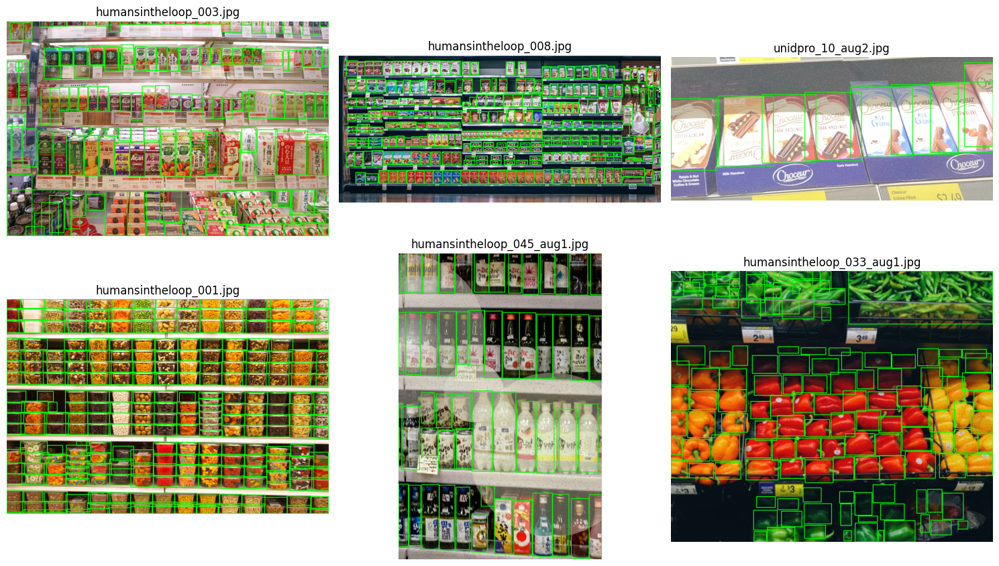

In [66]:
# 2.4 Verificación visual: 6 imágenes al azar con las cajas convertidas
imgs = list((OUT / "images" / "train").glob("*"))
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for ax, p in zip(axs.ravel(), random.sample(imgs, min(6, len(imgs)))):
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    lab = OUT / "labels" / "train" / f"{p.stem}.txt"
    for ln in lab.read_text().splitlines():
        _, cx, cy, bw, bh = map(float, ln.split())
        cv2.rectangle(im, (int((cx-bw/2)*w), int((cy-bh/2)*h)),
                          (int((cx+bw/2)*w), int((cy+bh/2)*h)), (0, 255, 0), 2)
    ax.imshow(im); ax.set_title(p.name[:30]); ax.axis("off")
plt.tight_layout(); plt.show()
# Comprobar que no queden cajas sobre etiquetas de precio.

## 3. Aumentación (solo imágenes de entrenamiento)
Se generan copias alteradas de cada imagen de `train`, con sus cajas transformadas, para que el detector aprenda a tolerar fallas de captura: flash o reflejos, desenfoque, píxeles muertos, ruido, blanco y negro y cambios de ángulo (perspectiva).

Reglas: nunca se aumenta `val` ni las fotos de prueba, y las copias llevan el sufijo `_aug` para poder regenerarlas sin acumular corridas anteriores. La función sirve para cualquier carpeta YOLO, por lo que más adelante se aplica igual a las fotos propias de entrenamiento.

In [67]:
# 3.1 Pipeline de aumentación y función que la aplica a una carpeta YOLO
import albumentations as A

AUG = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Perspective(scale=(0.05, 0.12), p=0.5),                         # cambio de ángulo
    A.OneOf([A.RandomSunFlare(src_radius=250, p=1.0),                 # flash / reflejo
             A.RandomBrightnessContrast(brightness_limit=(0.2, 0.5), contrast_limit=0.2, p=1.0)], p=0.5),
    A.OneOf([A.GaussianBlur(blur_limit=(3, 7), p=1.0),
             A.MotionBlur(blur_limit=(5, 11), p=1.0)], p=0.4),        # desenfoque
    A.OneOf([A.PixelDropout(dropout_prob=0.01, drop_value=0, p=1.0),
             A.PixelDropout(dropout_prob=0.01, drop_value=255, p=1.0)], p=0.4),   # píxeles muertos
    A.ISONoise(p=0.3),
    A.ToGray(p=0.2),                                                  # blanco y negro
], bbox_params=A.BboxParams(format="albumentations", label_fields=["clases"], min_visibility=0.3))

def aumentar_train(carpeta, copias=3):
    carpeta = Path(carpeta)
    for f in carpeta.rglob("*_aug*"):            # limpia corridas anteriores
        f.unlink()
    n = 0
    for img_p in sorted((carpeta / "images" / "train").glob("*")):
        lab_p = carpeta / "labels" / "train" / f"{img_p.stem}.txt"
        if not lab_p.exists():
            continue
        filas = [l.split() for l in lab_p.read_text().splitlines() if l.strip()]
        cajas, clases = [], []
        for f in filas:                          # YOLO (cx,cy,w,h) -> esquinas normalizadas dentro de [0,1]
            c, cx, cy, w, h = int(f[0]), *map(float, f[1:])
            x1, y1 = max(0.0, cx - w / 2), max(0.0, cy - h / 2)
            x2, y2 = min(1.0, cx + w / 2), min(1.0, cy + h / 2)
            if x2 - x1 > 1e-4 and y2 - y1 > 1e-4:
                cajas.append([x1, y1, x2, y2]); clases.append(c)
        if not cajas:
            continue
        im = cv2.imread(str(img_p))
        s = 1280 / max(im.shape[:2])
        if s < 1:                                  # defensa: reduce fotos grandes antes de alterarlas
            im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        for k in range(copias):
            r = AUG(image=im, bboxes=cajas, clases=clases)
            if not r["bboxes"]:
                continue
            nombre = f"{img_p.stem}_aug{k}"
            cv2.imwrite(str(carpeta / "images" / "train" / f"{nombre}.jpg"),
                        cv2.cvtColor(r["image"], cv2.COLOR_RGB2BGR))
            lineas = [f"{c} {(b[0]+b[2])/2:.6f} {(b[1]+b[3])/2:.6f} {b[2]-b[0]:.6f} {b[3]-b[1]:.6f}"
                      for c, b in zip(r["clases"], r["bboxes"])]
            (carpeta / "labels" / "train" / f"{nombre}.txt").write_text("\n".join(lineas))
            n += 1
        del im; gc.collect()                       # libera RAM tras cada imagen
    print(f"{n} imágenes aumentadas generadas en train")

train originales: 52 | train total: 208


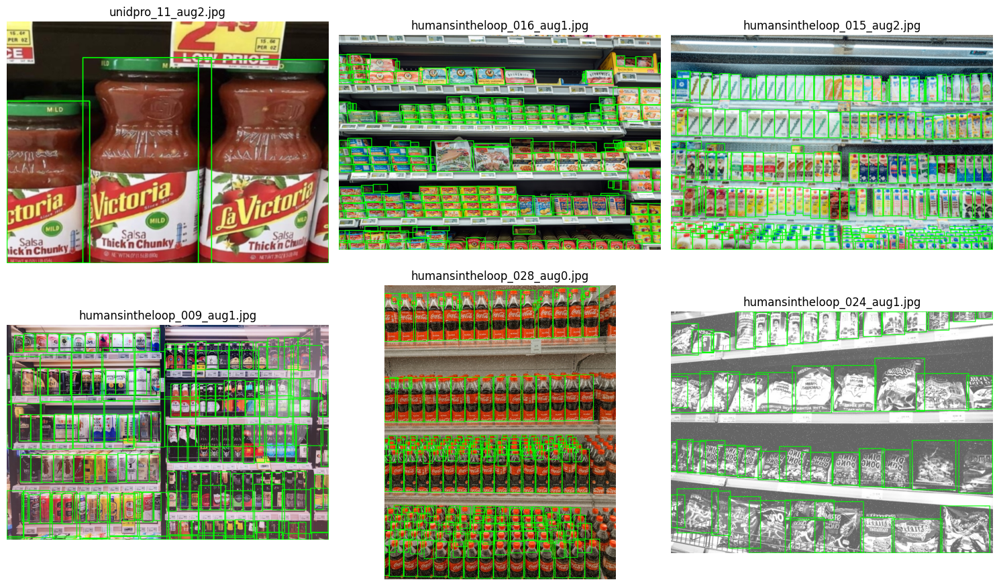

In [68]:
# 3.2 Aplicar la aumentación a los datos públicos, guardar en Drive y revisar el resultado
N_COPIAS = 3
if not DATOS_LISTOS:                              # si los datos vinieron de Drive, ya están aumentados
    aumentar_train(OUT, copias=N_COPIAS)
    guardar_cache("yolo_productos", OUT)          # datos convertidos y aumentados: 1 solo .zip en Drive
    DATOS_LISTOS = True

todas = list((OUT / "images" / "train").glob("*"))
print("train originales:", len([p for p in todas if "_aug" not in p.name]), "| train total:", len(todas))

aug_imgs = [p for p in todas if "_aug" in p.name]
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for ax, p in zip(axs.ravel(), random.sample(aug_imgs, min(6, len(aug_imgs)))):
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    for ln in (OUT / "labels" / "train" / f"{p.stem}.txt").read_text().splitlines():
        _, cx, cy, bw, bh = map(float, ln.split())
        cv2.rectangle(im, (int((cx-bw/2)*w), int((cy-bh/2)*h)),
                          (int((cx+bw/2)*w), int((cy+bh/2)*h)), (0, 255, 0), 2)
    ax.imshow(im); ax.set_title(p.name[:32]); ax.axis("off")
plt.tight_layout(); plt.show()
# Comprobar que las cajas siguen sobre los productos tras el cambio de perspectiva.

## 4. Detector de productos (YOLOv8)
Se entrena un modelo **YOLOv8s** (preentrenado en COCO) para detectar una única clase, `producto`, con los datasets públicos filtrados y aumentados de las secciones 2 y 3. Es la **línea base** del proyecto: las fotos propias no participan en este entrenamiento y se reservan para evaluar.

- **Entrada:** `train` (imágenes originales más copias aumentadas) y `val` (sin aumentar).
- **Salida:** pesos `best.pt`, métricas (mAP@0.5, mAP@0.5:0.95, precision y recall) y predicciones de ejemplo.
- **Uso posterior:** los productos detectados definen los espacios libres de cada repisa (sección 6), a partir de los cuales se calcula el porcentaje de stock y la alerta de reabastecimiento.

Las métricas de esta sección se miden sobre datasets públicos y sirven para verificar el entrenamiento; el resultado final del proyecto se evalúa sobre las fotos propias.

In [69]:
# 4.1 Entrenamiento del detector de productos (YOLOv8s, GPU T4), reanudable y guardado en Drive
from ultralytics import YOLO

RUNS = DRIVE / "runs"                     # los checkpoints viven en Drive: si Colab se cae, se reanuda
RUN  = RUNS / "productos_v1"
BEST = RUN / "weights" / "best.pt"
LAST = RUN / "weights" / "last.pt"
HECHO = RUN / "terminado.txt"             # marca de entrenamiento completo

if HECHO.exists() and not REENTRENAR:
    print("Modelo ya entrenado, se reutiliza:", BEST)
elif LAST.exists() and not REENTRENAR:
    print("Reanudando entrenamiento interrumpido...")
    YOLO(LAST).train(resume=True)
    HECHO.write_text("ok")
else:
    shutil.rmtree(RUN, ignore_errors=True)
    YOLO("yolov8s.pt").train(             # preentrenado en COCO; "s" es buen equilibrio para la T4 gratis
        data=str(OUT / "data.yaml"),
        epochs=80, patience=20,           # se detiene antes si deja de mejorar
        imgsz=640, batch=8,
        workers=2, seed=SEED,
        project=str(RUNS), name="productos_v1", exist_ok=True,
    )
    HECHO.write_text("ok")
print("Mejores pesos:", BEST)

Modelo ya entrenado, se reutiliza: /content/drive/MyDrive/proyecto_gondolas/runs/productos_v1/weights/best.pt
Mejores pesos: /content/drive/MyDrive/proyecto_gondolas/runs/productos_v1/weights/best.pt


In [70]:
# 4.2 Métricas en validación (datasets públicos; no son tus fotos propias)
m = YOLO(BEST).val(data=str(OUT / "data.yaml"), imgsz=640, max_det=500, verbose=False)
print(f"mAP@0.5: {m.box.map50:.3f} | mAP@0.5:0.95: {m.box.map:.3f} | "
      f"Precision: {m.box.mp:.3f} | Recall: {m.box.mr:.3f}")

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2169.2±670.0 MB/s, size: 357.2 KB)
val: Scanning /content/proyecto/yolo_productos/labels/val... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 686.4it/s 0.0s
val: New cache created: /content/proyecto/yolo_productos/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.9it/s 0.5s
                   all          8       1125      0.803      0.574      0.615      0.337
Speed: 0.5ms preprocess, 17.1ms inference, 0.0ms loss, 4.2ms postprocess per image
Results saved to /content/runs/detect/val-3
mAP@0.5: 0.615 | mAP@0.5:0.95: 0.337 | Precision: 0.803 | Recall: 0.574


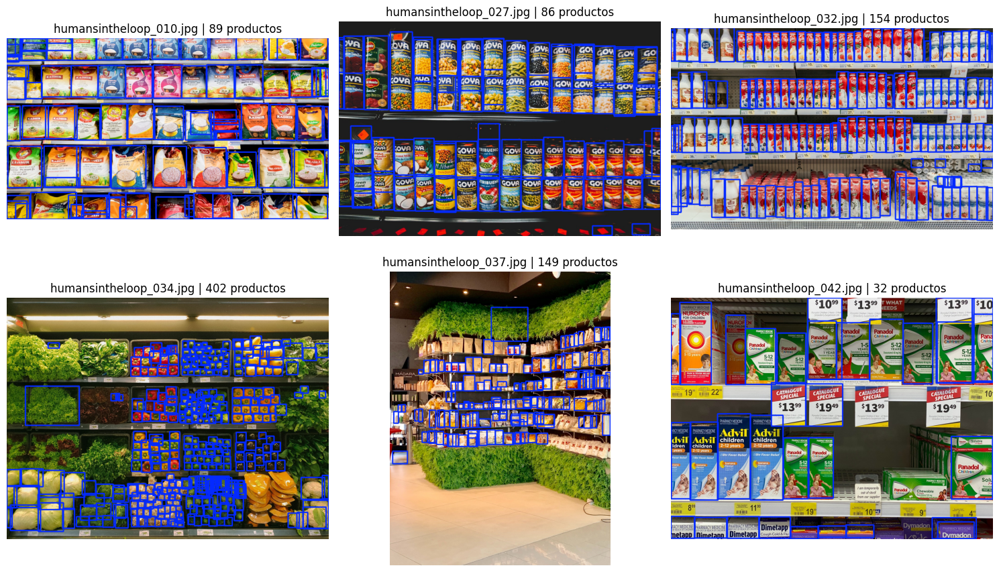

In [71]:
# 4.3 Predicciones visuales en imágenes de validación
detector = YOLO(BEST)
val_imgs = sorted((OUT / "images" / "val").glob("*"))[:6]
preds = detector.predict([str(p) for p in val_imgs], conf=0.25, imgsz=640, max_det=500, verbose=False)

fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for ax, r, p in zip(axs.ravel(), preds, val_imgs):
    ax.imshow(r.plot(labels=False, conf=False)[..., ::-1])    # BGR -> RGB
    ax.set_title(f"{p.name[:28]} | {len(r.boxes)} productos"); ax.axis("off")
plt.tight_layout(); plt.show()

44 fotos propias encontradas


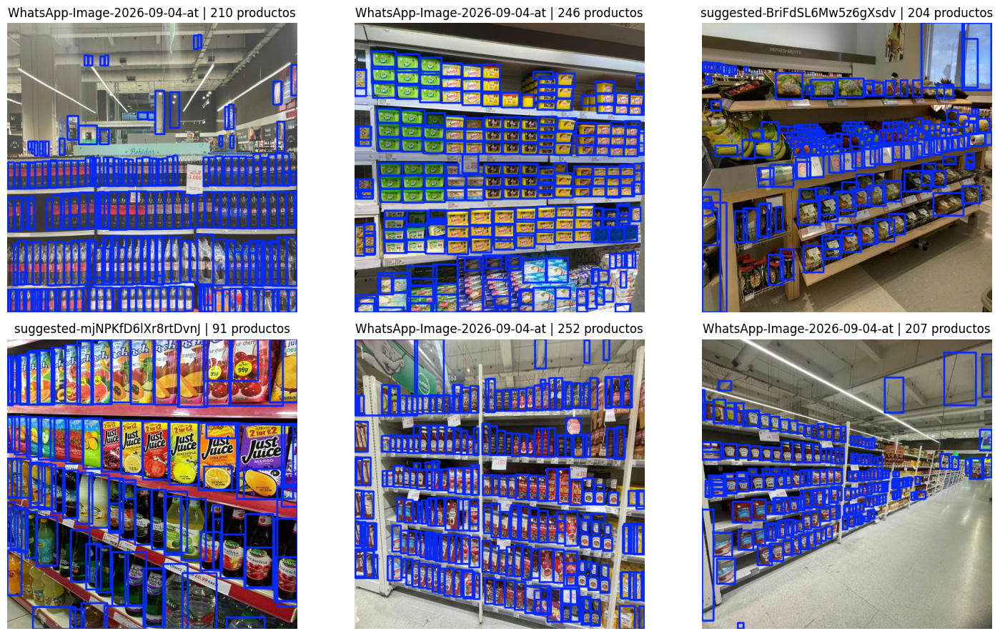

{'WhatsApp-Image-2026-09-04-at-9-01-41-PM_jpeg.rf.52102eafb16141613de5a699e81f09c9.jpg': 210, 'WhatsApp-Image-2026-09-04-at-9-02-49-PM_jpeg.rf.c19f33678fa060140a41163b01488d99.jpg': 246, 'suggested-BriFdSL6Mw5z6gXsdvlh_jpg.rf.26933896b63e4b4bc08d9b328c08fdde.jpg': 204, 'suggested-mjNPKfD6lXr8rtDvnJOB_jpg.rf.a6a8e0ef0e7bd6530275d4e1358f449c.jpg': 91, 'WhatsApp-Image-2026-09-04-at-9-01-23-PM-1-_jpeg.rf.1931e553f1b887322b4782a37f778b76.jpg': 252, 'WhatsApp-Image-2026-09-04-at-9-01-23-PM_jpeg.rf.7934ec92387f3d950c7cdafca3ebbe6f.jpg': 207, 'WhatsApp-Image-2026-09-04-at-9-01-24-PM_jpeg.rf.5d4ca5a196841a0ab7b8138c26d2ea4b.jpg': 321, 'WhatsApp-Image-2026-09-04-at-9-01-25-PM-1-_jpeg.rf.52ad146ec3bcf94a054c459fe24797c6.jpg': 229, 'WhatsApp-Image-2026-09-04-at-9-01-25-PM_jpeg.rf.22753b8a8871ba8eee18c9ea9536dd0e.jpg': 305, 'WhatsApp-Image-2026-09-04-at-9-01-28-PM_jpeg.rf.ba88386afbbfaea195f7b5e0aaaf8009.jpg': 365, 'WhatsApp-Image-2026-09-04-at-9-01-30-PM_jpeg.rf.0e3927dabafaf9fde119af558ff9d034.jp

In [72]:
# 5.1 Detector de productos sobre las fotos propias (Roboflow)
detector = YOLO(BEST)
fotos = sorted(p for p in PROPIO.rglob("*") if p.suffix.lower() in IMG_EXT)
print(len(fotos), "fotos propias encontradas")

conteo = {}
fig, axs = plt.subplots(2, 3, figsize=(15, 9)); ejes = iter(axs.ravel())
resultados = detector.predict([str(p) for p in fotos], conf=0.25, imgsz=960,
                              max_det=500, stream=True, verbose=False)   # stream: no acumula todo en RAM
for p, r in zip(fotos, resultados):
    conteo[p.name] = len(r.boxes)
    ax = next(ejes, None)
    if ax is not None:                                  # se dibujan solo las primeras 6
        ax.imshow(r.plot(labels=False, conf=False)[..., ::-1])
        ax.set_title(f"{p.name[:28]} | {len(r.boxes)} productos"); ax.axis("off")
plt.tight_layout(); plt.show()
print(conteo)

In [73]:
# 6.1 Fotos propias: clases por partición y conversión de `repisa` a formato YOLO-seg
REPISA_CLASES = ["Gondolas"]      # nombre de la clase en Roboflow (sin distinguir mayúsculas)

# --- Inspección: imágenes y anotaciones por partición del export COCO de Roboflow ---
particiones = {}                # nombre interno -> (carpeta en el export, json, id->nombre de clase)
for interno, carpeta in {"train": "train", "val": "valid", "test": "test"}.items():
    j = PROPIO / carpeta / "_annotations.coco.json"
    if not j.exists():
        continue
    d = json.load(open(j))
    cats = {c["id"]: c["name"] for c in d["categories"]}
    cnt = collections.Counter(cats[a["category_id"]] for a in d["annotations"])
    imgs_por_clase = collections.defaultdict(set)
    for a in d["annotations"]:
        imgs_por_clase[cats[a["category_id"]]].add(a["image_id"])
    print(f"{interno:5s} | {len(d['images'])} imágenes | anotaciones: {dict(cnt)} | "
          f"imágenes con cada clase: { {k: len(v) for k, v in imgs_por_clase.items()} }")
    particiones[interno] = (carpeta, d, cats)

# --- Conversión de `repisa` a YOLO-seg (polígonos normalizados; si solo hay caja, se usa como rectángulo) ---
OUT_REP = BASE / "yolo_repisas"
shutil.rmtree(OUT_REP, ignore_errors=True)
nombres_repisa = [c.lower() for c in REPISA_CLASES]

def poligonos(a):
    segs = [s for s in (a.get("segmentation") or []) if isinstance(s, list) and len(s) >= 6]
    if segs:
        return segs
    x, y, w, h = a["bbox"]
    return [[x, y, x + w, y, x + w, y + h, x, y + h]]

for interno, (carpeta, d, cats) in particiones.items():
    (OUT_REP / "images" / interno).mkdir(parents=True, exist_ok=True)
    (OUT_REP / "labels" / interno).mkdir(parents=True, exist_ok=True)
    por_imagen = collections.defaultdict(list)
    for a in d["annotations"]:
        if cats[a["category_id"]].lower() in nombres_repisa:
            por_imagen[a["image_id"]].append(a)
    usadas = 0
    for im in d["images"]:
        src = PROPIO / carpeta / im["file_name"]
        if im["id"] not in por_imagen or not src.exists():
            continue
        w, h = im["width"], im["height"]
        lineas = []
        for a in por_imagen[im["id"]]:
            for seg in poligonos(a):
                pts = [f"{min(max(v / (w if i % 2 == 0 else h), 0), 1):.6f}" for i, v in enumerate(seg)]
                lineas.append("0 " + " ".join(pts))
        foto = Image.open(src).convert("RGB")
        foto.thumbnail((1280, 1280))                      # las coordenadas son normalizadas: no cambian
        foto.save(OUT_REP / "images" / interno / f"{src.stem}.jpg", quality=92)
        (OUT_REP / "labels" / interno / f"{src.stem}.txt").write_text("\n".join(lineas))
        usadas += 1
    print(f"{interno}: {usadas} imágenes con repisa convertidas")

(OUT_REP / "data.yaml").write_text(
    f"path: {OUT_REP}\ntrain: images/train\nval: images/{'val' if 'val' in particiones else 'test'}\n"
    f"test: images/test\nnames:\n  0: repisa\n")

train | 31 imágenes | anotaciones: {'Gondolas': 51} | imágenes con cada clase: {'Gondolas': 31}
val   | 9 imágenes | anotaciones: {'Gondolas': 18} | imágenes con cada clase: {'Gondolas': 9}
test  | 4 imágenes | anotaciones: {'Gondolas': 4} | imágenes con cada clase: {'Gondolas': 4}
train: 31 imágenes con repisa convertidas
val: 9 imágenes con repisa convertidas
test: 4 imágenes con repisa convertidas


110

train 31 imágenes -> 31 fotos originales distintas
val 9 imágenes -> 9 fotos originales distintas
test 4 imágenes -> 4 fotos originales distintas
Modelo ya entrenado, se reutiliza: /content/drive/MyDrive/proyecto_gondolas/runs/gondolas_seg_v1/weights/best.pt
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8s-seg summary (fused): 85 layers, 11,779,987 parameters, 0 gradients, 39.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2094.5±502.1 MB/s, size: 88.8 KB)
val: Scanning /content/proyecto/yolo_repisas/labels/val... 9 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 9/9 1.6Kit/s 0.0s
val: New cache created: /content/proyecto/yolo_repisas/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.8it/s 0.4s
                   all          9         18     0.0154      0.722     0.0151    0.00626     0.0105      0.333   

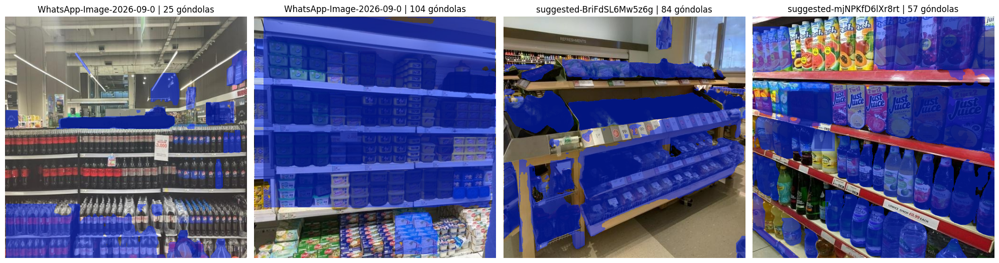

In [74]:
# 6.2 Segmentación de góndolas (YOLOv8-seg): reanudable, guardada en Drive y con evaluación

# Conteo de fotos originales por partición (para saber cuántas hay detrás de las copias aumentadas de Roboflow)
for interno, (carpeta, d, cats) in particiones.items():
    originales = {im["file_name"].split(".rf.")[0] for im in d["images"]}
    print(interno, len(d["images"]), "imágenes ->", len(originales), "fotos originales distintas")

if not (DRIVE / "yolo_repisas.zip").exists():
    guardar_cache("yolo_repisas", OUT_REP)           # respaldo del dataset convertido

RUN_SEG   = DRIVE / "runs" / "gondolas_seg_v1"
BEST_SEG  = RUN_SEG / "weights" / "best.pt"
LAST_SEG  = RUN_SEG / "weights" / "last.pt"
HECHO_SEG = RUN_SEG / "terminado.txt"

if HECHO_SEG.exists() and not REENTRENAR:
    print("Modelo ya entrenado, se reutiliza:", BEST_SEG)
elif LAST_SEG.exists() and not REENTRENAR:
    print("Reanudando entrenamiento interrumpido...")
    YOLO(LAST_SEG).train(resume=True)
    HECHO_SEG.write_text("ok")
else:
    shutil.rmtree(RUN_SEG, ignore_errors=True)
    YOLO("yolov8s-seg.pt").train(
        data=str(OUT_REP / "data.yaml"),
        epochs=100, patience=25,
        imgsz=640, batch=8, workers=2, seed=SEED,
        project=str(DRIVE / "runs"), name="gondolas_seg_v1", exist_ok=True,
    )
    HECHO_SEG.write_text("ok")

# --- Métricas en validación y en prueba ---
seg = YOLO(BEST_SEG)
for split in ("val", "test"):
    m = seg.val(data=str(OUT_REP / "data.yaml"), split=split, imgsz=640, verbose=False)
    print(f"{split}: mAP@0.5 caja = {m.box.map50:.3f} | mAP@0.5 máscara = {m.seg.map50:.3f} | "
          f"mAP@0.5:0.95 máscara = {m.seg.map:.3f}")

# --- Máscaras predichas sobre las fotos de prueba ---
test_imgs = sorted((OUT_REP / "images" / "test").glob("*"))
res = seg.predict([str(p) for p in test_imgs], conf=0.25, imgsz=640, verbose=False)
fig, axs = plt.subplots(1, len(res), figsize=(5 * len(res), 6))
for ax, r, p in zip(np.atleast_1d(axs), res, test_imgs):
    ax.imshow(r.plot(labels=False, boxes=False, conf=False)[..., ::-1])
    ax.set_title(f"{p.name[:24]} | {len(r.boxes)} góndolas"); ax.axis("off")
plt.tight_layout(); plt.show()

44 fotos | GPU activa: True
WhatsApp-Image-2026-09-04-at detección   0.0s | filtro y filas  0.00s | dibujo   0.0s
WhatsApp-Image-2026-09-04-at detección   0.0s | filtro y filas  0.00s | dibujo   0.0s
suggested-BriFdSL6Mw5z6gXsdv detección   0.0s | filtro y filas  0.00s | dibujo   0.0s
suggested-mjNPKfD6lXr8rtDvnJ detección   0.0s | filtro y filas  0.00s | dibujo   0.0s
WhatsApp-Image-2026-09-04-at detección   0.0s | filtro y filas  0.00s | dibujo   0.0s
WhatsApp-Image-2026-09-04-at detección   0.0s | filtro y filas  0.00s | dibujo   0.0s


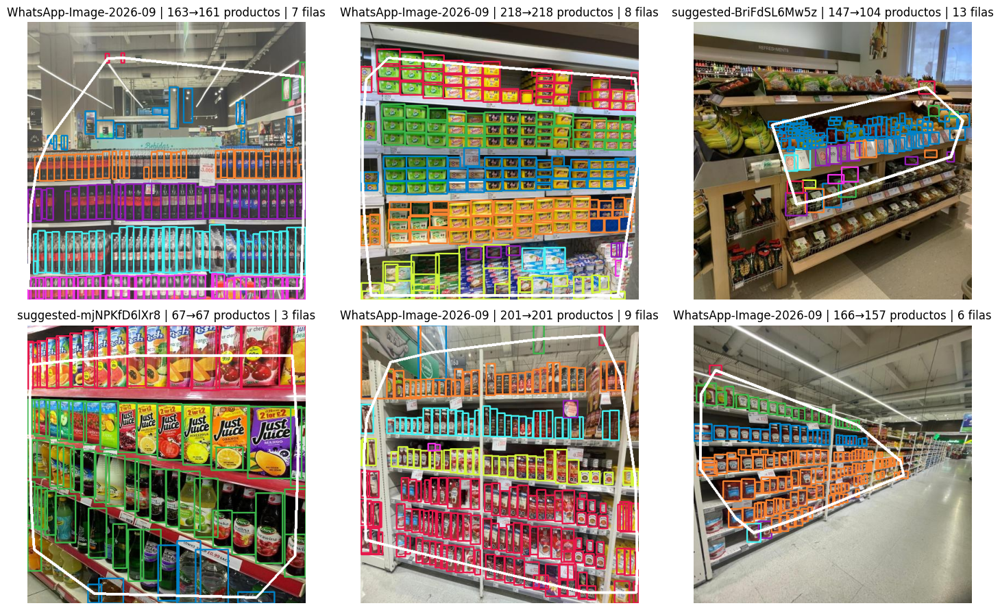

In [75]:
# 6.3 (versión sin sklearn) Zona de la góndola y filas a partir de los productos detectados
import time
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from ultralytics import YOLO

BEST = DRIVE / "runs" / "productos_v1" / "weights" / "best.pt"
detector = YOLO(BEST)
PROPIO = BASE / "propio"
fotos = sorted(p for p in PROPIO.rglob("*") if p.suffix.lower() in IMG_EXT)
print(len(fotos), "fotos | GPU activa:", torch.cuda.is_available(), flush=True)

CACHE_DET = globals().get("CACHE_DET", {})
def productos(path, conf=0.30, iou=0.5):
    clave = (str(path), conf, iou)
    if clave not in CACHE_DET:                     # una foto ya detectada no se vuelve a procesar
        r = detector.predict(str(path), conf=conf, iou=iou, imgsz=960, max_det=500, verbose=False)[0]
        CACHE_DET[clave] = r.boxes.xyxy.cpu().numpy()
    return CACHE_DET[clave]

def quitar_aislados(b, eps=3.0, rel=0.2):
    # Une cajas cercanas (distancia medida en tamaños de producto) y conserva solo los grupos grandes
    ancho, alto = np.median(b[:, 2] - b[:, 0]), np.median(b[:, 3] - b[:, 1])
    c = np.c_[(b[:, 0] + b[:, 2]) / 2 / ancho, (b[:, 1] + b[:, 3]) / 2 / alto]
    d = np.sqrt(((c[:, None, :] - c[None, :, :]) ** 2).sum(-1))
    _, lab = connected_components(csr_matrix(d < eps), directed=False)
    tam = np.bincount(lab)
    return b[np.isin(lab, np.where(tam >= rel * tam.max())[0])]

def agrupar_filas(b, tol=0.35):
    # Filas por la altura de la base de cada producto (y2); se corta cuando el salto supera tol x alto mediano
    alto = np.median(b[:, 3] - b[:, 1])
    orden = np.argsort(b[:, 3]); fila = np.zeros(len(b), int); k = 0
    for i in range(1, len(b)):
        if b[orden[i], 3] - b[orden[i - 1], 3] > tol * alto:
            k += 1
        fila[orden[i]] = k
    return fila

PALETA = [(230, 25, 75), (60, 180, 75), (0, 130, 200), (245, 130, 48), (145, 30, 180),
          (70, 240, 240), (240, 50, 230), (210, 245, 60)]

fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for ax, p in zip(axs.ravel(), fotos[:6]):
    t0 = time.time(); b = productos(p); t1 = time.time()
    n0 = len(b); b = quitar_aislados(b); fila = agrupar_filas(b); t2 = time.time()
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    s = min(1.0, 1000 / max(im.shape[:2]))         # se dibuja en tamaño reducido (máx. 1000 px)
    im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA); b = b * s
    for (x1, y1, x2, y2), f in zip(b.astype(int), fila):
        cv2.rectangle(im, (x1, y1), (x2, y2), PALETA[f % len(PALETA)], 2)
    casco = cv2.convexHull(np.c_[(b[:, 0] + b[:, 2]) / 2, (b[:, 1] + b[:, 3]) / 2].astype(np.int32))
    cv2.polylines(im, [casco], True, (255, 255, 255), 4)
    ax.imshow(im); ax.axis("off")
    ax.set_title(f"{p.name[:22]} | {n0}→{len(b)} productos | {fila.max() + 1} filas")
    print(f"{p.name[:28]:28s} detección {t1-t0:5.1f}s | filtro y filas {t2-t1:5.2f}s | dibujo {time.time()-t2:5.1f}s", flush=True)
plt.tight_layout(); plt.show()

WhatsApp-Image-2026-09-04-at filas:4 | stock góndola 91% | por fila: ['81%', '96%', '89%', '100%']
WhatsApp-Image-2026-09-04-at filas:4 | stock góndola 100% | por fila: ['100%', '100%', '100%', '100%']
suggested-BriFdSL6Mw5z6gXsdv filas:1 | stock góndola 100% | por fila: ['100%']
suggested-mjNPKfD6lXr8rtDvnJ filas:4 | stock góndola 95% | por fila: ['100%', '82%', '100%', '100%']
WhatsApp-Image-2026-09-04-at filas:1 | stock góndola 96% | por fila: ['96%']
WhatsApp-Image-2026-09-04-at filas:1 | stock góndola 98% | por fila: ['98%']


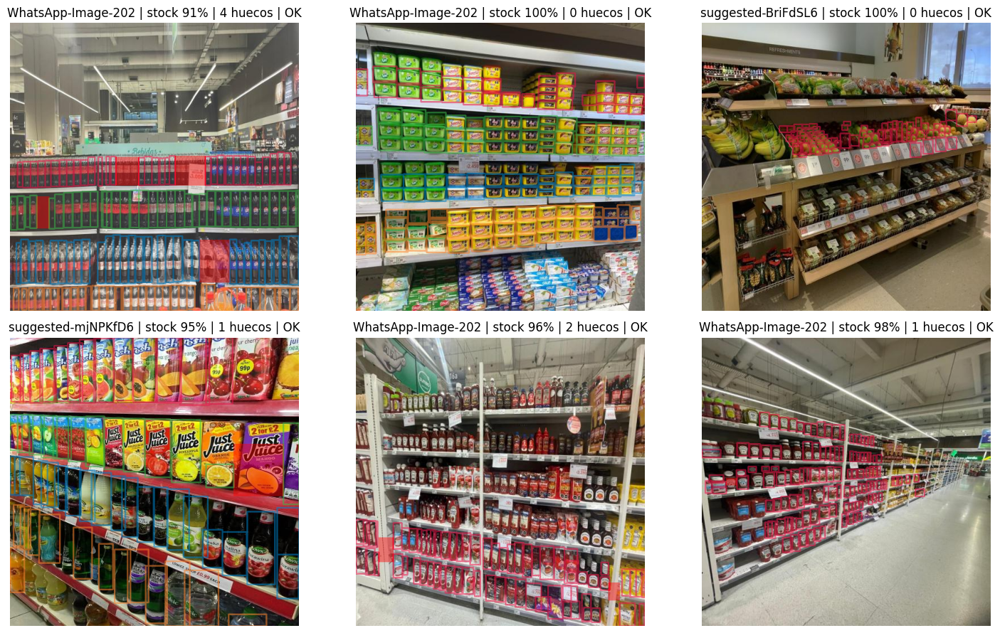

In [77]:
# 6.4 Filas corregidas por inclinación + huecos + stock % + alerta
K_HUECO, MIN_FILA, BORDES = 1.3, 0.5, False   # hueco si ancho > 1.3 × producto | filas ≥ 50% de la mayor | sin huecos de borde

def pendiente(b):
    cx = (b[:, 0] + b[:, 2]) / 2; y2 = b[:, 3]
    w, h = np.median(b[:, 2] - b[:, 0]), np.median(b[:, 3] - b[:, 1]); s = []
    for i in range(len(b)):
        m = (cx - cx[i] > 0) & (cx - cx[i] < 3 * w) & (abs(y2 - y2[i]) < 0.5 * h)
        s += list((y2[m] - y2[i]) / (cx[m] - cx[i]))
    return np.median(s) if s else 0.0

def analizar(b, k=K_HUECO, min_fila=MIN_FILA):
    a = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    b = b[(a > 0.4 * np.median(a)) & (a < 2.5 * np.median(a))]   # descarta productos del fondo (tamaño atípico)
    b2 = b.copy(); b2[:, 3] -= pendiente(b) * (b[:, 0] + b[:, 2]) / 2     # endereza las bases
    fila = agrupar_filas(b2)
    cuentas = np.bincount(fila)
    ok = np.isin(fila, np.where(cuentas >= min_fila * cuentas.max())[0])
    b, fila = b[ok], fila[ok]
    _, fila = np.unique(fila, return_inverse=True)
    x_ini, x_fin = b[:, 0].min(), b[:, 2].max()                           # extensión de la góndola
    filas, huecos = [], []
    for f in range(fila.max() + 1):
        r = b[fila == f]; r = r[np.argsort(r[:, 0])]
        med = np.median(r[:, 2] - r[:, 0]); unidades = 0.0
        tramos = ([(x_ini, r[0, 0], r[0])] if BORDES else []) + \
                 [(r[i, 2], r[i + 1, 0], (r[i] + r[i + 1]) / 2) for i in range(len(r) - 1)] + \
                 ([(r[-1, 2], x_fin, r[-1])] if BORDES else [])
        for xa, xb, ref in tramos:
            if xb - xa > k * med:
                huecos.append((xa, ref[1], xb, ref[3], f)); unidades += (xb - xa) / med
        filas.append((len(r), unidades, len(r) / (len(r) + unidades)))
    n = sum(x[0] for x in filas); u = sum(x[1] for x in filas)
    return b, fila, huecos, filas, n / (n + u)

fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for ax, p in zip(axs.ravel(), fotos[:6]):
    b = quitar_aislados(productos(p))
    b, fila, huecos, filas, stock = analizar(b)
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    s = min(1.0, 1000 / max(im.shape[:2]))
    im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    ov = im.copy()
    for (x1, y1, x2, y2), f in zip((b * s).astype(int), fila):
        cv2.rectangle(im, (x1, y1), (x2, y2), PALETA[f % len(PALETA)], 2)
    for x1, y1, x2, y2, f in huecos:
        cv2.rectangle(ov, (int(x1 * s), int(y1 * s)), (int(x2 * s), int(y2 * s)), (255, 0, 0), -1)
    im = cv2.addWeighted(ov, 0.45, im, 0.55, 0)
    ax.imshow(im); ax.axis("off")
    alerta = "⚠ REABASTECER" if stock < 0.30 else "OK"
    ax.set_title(f"{p.name[:18]} | stock {stock:.0%} | {len(huecos)} huecos | {alerta}")
    print(f"{p.name[:28]:28s} filas:{len(filas)} | stock góndola {stock:.0%} | por fila:",
          [f"{x[2]:.0%}" + ("⚠" if x[2] < 0.30 else "") for x in filas])
plt.tight_layout(); plt.show()